# Projeto Integrador - Flávia Ferreira

**Arquivo utilizado:** `BALANCO_ENERGIA_SUBSISTEMA_2023.csv, BALANCO_ENERGIA_SUBSISTEMA_2024.csv e BALANCO_ENERGIA_SUBSISTEMA_2025.csv`  
**Pergunta:** Qual a importância da energia renovável (eólica e solar) no NE para atendimento a carga do Brasil no período de 2023 a 2025?  
**Fonte:** Operador Nacional do Sistema Elétrico — Portal de Dados Abertos · 
**Conjunto:** Balanço de Energia nos Subsistemas · 
**Período:** 01/01/2023 a 31/12/2025 ·
**Granularidade:** Uma linha por instante horário e identificação de subsistema ·
**Volume:** 131.520 linhas e 9 colunas ·
**Formato:** CSV UTF-8, separado por ponto e vírgula · 
**Licença:** Creative Commons Atribuição (CC BY), conforme o portal ·
**Página oficial:** https://dados.ons.org.br/dataset/balanco-energia-subsistema


Mantenha este notebook e o CSV na mesma pasta. Execute as células na ordem apresentada. Se precisar instalar as bibliotecas, use em um terminal:

python -m pip install jupyterlab ipykernel numpy pandas matplotlib seaborn plotly
``


In [1]:
pip install numpy pandas matplotlib seaborn plotly

Note: you may need to restart the kernel to use updated packages.


## 1. Ambiente e bibliotecas


In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)


Python: 3.14.4
pandas: 3.1.1


## 2. Caminho relativo e carregamento


In [3]:
df2023 = pd.read_csv('BALANCO_ENERGIA_SUBSISTEMA_2023.csv', sep=";")
print('Base_Dados_Aula_Carga_Energia_2023.csv')
print('Dimensão base 2023 =', df2023.shape)
df2024 = pd.read_csv('BALANCO_ENERGIA_SUBSISTEMA_2024.csv', sep=";")
print('Base_Dados_Aula_Carga_Energia_2024.csv')
print('Dimensão base 2024 =', df2024.shape)
df2025 = pd.read_csv('BALANCO_ENERGIA_SUBSISTEMA_2025.csv', sep=";")
print('Base_Dados_Aula_Carga_Energia_2025.csv')
print('Dimensão base 2025 =', df2025.shape)

Base_Dados_Aula_Carga_Energia_2023.csv
Dimensão base 2023 = (43800, 9)
Base_Dados_Aula_Carga_Energia_2024.csv
Dimensão base 2024 = (43920, 9)
Base_Dados_Aula_Carga_Energia_2025.csv
Dimensão base 2025 = (43800, 9)


## 3. Primeiras inspeções
Como resultado das primeiras inspeções verificamos que a base de 2023 e 2025 tem a mesma quantidade de linhas e colunas, enquanto que a base de dados de 2024 tem 120 linhas a mais, pois trata-se de um ano bissexto. Como são 4 subsistemas NE, N, S, SE e o SIN, temos mais 5x24 linhas na base de dados de 2024. Conforme pode ser verificado com o código abaixo.


In [4]:
display(df2023.head(3))
display(df2023.tail(3))
df2023.info()
display(df2024.head(3))
display(df2024.tail(3))
df2024.info()
display(df2025.head(3))
display(df2025.tail(3))
df2025.info()


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2023-01-01 00:00:00,3874.072998,677.062988,13305.261719,1.932,10455.818,7402.512
1,N,NORTE,2023-01-01 00:00:00,7858.744141,877.854980,211.772003,0.000,5990.553,2957.818
2,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01 00:00:00,39057.309000,5698.335000,14138.750000,21.155,58904.080,11.470


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
43797,SIN,SISTEMA INTERLIGADO NACIONAL,2023-12-31 23:00:00,52629.359000,8982.848000,3588.314000,11.241,65212.050,-0.290
43798,SE,SUDESTE/CENTRO-OESTE,2023-12-31 23:00:00,32794.011719,5073.425781,8.500000,8.692,36060.076,1824.555
43799,S,SUL,2023-12-31 23:00:00,13067.818359,994.448975,622.163025,1.000,10365.647,4319.783


<class 'pandas.DataFrame'>
RangeIndex: 43800 entries, 0 to 43799
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_subsistema      43800 non-null  str    
 1   nom_subsistema     43800 non-null  str    
 2   din_instante       43800 non-null  str    
 3   val_gerhidraulica  43800 non-null  float64
 4   val_gertermica     43800 non-null  float64
 5   val_gereolica      43800 non-null  float64
 6   val_gersolar       43800 non-null  float64
 7   val_carga          43800 non-null  float64
 8   val_intercambio    43800 non-null  float64
dtypes: float64(6), str(3)
memory usage: 3.0 MB


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2024-01-01 00:00:00,3503.61792,486.473999,2491.562988,1.550,11976.884,-5493.679
1,N,NORTE,2024-01-01 00:00:00,3006.38501,2469.684082,2.193000,0.000,6539.560,-1061.298
2,SIN,SISTEMA INTERLIGADO NACIONAL,2024-01-01 00:00:00,51266.26400,8982.283000,3205.270000,11.213,63465.030,0.000


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
43917,SIN,SISTEMA INTERLIGADO NACIONAL,2024-12-31 23:00:00,42864.227000,6764.975000,17990.187000,1.0,67620.390,0.000
43918,SE,SUDESTE/CENTRO-OESTE,2024-12-31 23:00:00,25332.611328,4449.137207,6.000000,0.0,36830.757,-7043.008
43919,S,SUL,2024-12-31 23:00:00,7904.457031,353.339996,1410.843994,1.0,10927.911,-1258.270


<class 'pandas.DataFrame'>
RangeIndex: 43920 entries, 0 to 43919
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_subsistema      43920 non-null  str    
 1   nom_subsistema     43920 non-null  str    
 2   din_instante       43920 non-null  str    
 3   val_gerhidraulica  43920 non-null  float64
 4   val_gertermica     43920 non-null  float64
 5   val_gereolica      43920 non-null  float64
 6   val_gersolar       43920 non-null  float64
 7   val_carga          43920 non-null  float64
 8   val_intercambio    43920 non-null  float64
dtypes: float64(6), str(3)
memory usage: 3.0 MB


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2025-01-01 00:00:00,2219.280,415.154,16070.653,0.0,12251.182,6453.905
1,N,NORTE,2025-01-01 00:00:00,6818.532,1576.087,401.685,0.0,7097.751,1698.553
2,SIN,SISTEMA INTERLIGADO NACIONAL,2025-01-01 00:00:00,40778.712,6835.338,17662.519,1.0,65277.570,0.000


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
43797,SIN,SISTEMA INTERLIGADO NACIONAL,2025-12-31 23:00:00,54541.992,8267.268,11872.449,1.0,74682.710,0.000
43798,SE,SUDESTE/CENTRO-OESTE,2025-12-31 23:00:00,27730.875,5679.691,187.179,0.0,42418.294,-8820.549
43799,S,SUL,2025-12-31 23:00:00,11883.133,158.417,587.178,1.0,11458.166,1171.562


<class 'pandas.DataFrame'>
RangeIndex: 43800 entries, 0 to 43799
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_subsistema      43800 non-null  str    
 1   nom_subsistema     43800 non-null  str    
 2   din_instante       43800 non-null  str    
 3   val_gerhidraulica  43800 non-null  float64
 4   val_gertermica     43800 non-null  float64
 5   val_gereolica      43800 non-null  float64
 6   val_gersolar       43800 non-null  float64
 7   val_carga          43800 non-null  float64
 8   val_intercambio    43800 non-null  float64
dtypes: float64(6), str(3)
memory usage: 3.0 MB


## 4. Seleção, cópia e preparação


In [5]:
df232425 = pd.concat(
    [
        df2023.assign(ano=2023),
        df2024.assign(ano=2024),
        df2025.assign(ano=2025)
    ],
    ignore_index=True
)
display(df232425.shape)
display(df232425.head())
df232425.info()

(131520, 10)

,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio,ano
0,NE,NORDESTE,2023-01-01 00:00:00,3874.072998,677.062988,13305.261719,1.932,10455.818,7402.512,2023
1,N,NORTE,2023-01-01 00:00:00,7858.744141,877.854980,211.772003,0.000,5990.553,2957.818,2023
2,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01 00:00:00,39057.309000,5698.335000,14138.750000,21.155,58904.080,11.470,2023
3,SE,SUDESTE/CENTRO-OESTE,2023-01-01 00:00:00,24661.111328,4071.576904,6.000000,18.223,32183.885,-3426.974,2023
4,S,SUL,2023-01-01 00:00:00,2663.381104,71.839996,615.716003,1.000,10273.827,-6921.890,2023


<class 'pandas.DataFrame'>
RangeIndex: 131520 entries, 0 to 131519
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id_subsistema      131520 non-null  str    
 1   nom_subsistema     131520 non-null  str    
 2   din_instante       131520 non-null  str    
 3   val_gerhidraulica  131520 non-null  float64
 4   val_gertermica     131520 non-null  float64
 5   val_gereolica      131520 non-null  float64
 6   val_gersolar       131520 non-null  float64
 7   val_carga          131520 non-null  float64
 8   val_intercambio    131520 non-null  float64
 9   ano                131520 non-null  int64  
dtypes: float64(6), int64(1), str(3)
memory usage: 10.0 MB


In [6]:
dados = df232425.rename(columns={
    "nom_subsistema": "subsistema",
    "din_instante": "data",
    }).copy()
dados['data'] = pd.to_datetime(dados['data'])
#dados["data"] = pd.to_datetime(dados["data"])
dados["mes"] = dados["data"].dt.month
dados["dia_semana"] = dados["data"].dt.day_name()
display(dados.head())
dados.info()


,id_subsistema,subsistema,data,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio,ano,mes,dia_semana
0,NE,NORDESTE,2023-01-01,3874.072998,677.062988,13305.261719,1.932,10455.818,7402.512,2023,1,Sunday
1,N,NORTE,2023-01-01,7858.744141,877.854980,211.772003,0.000,5990.553,2957.818,2023,1,Sunday
2,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01,39057.309000,5698.335000,14138.750000,21.155,58904.080,11.470,2023,1,Sunday
3,SE,SUDESTE/CENTRO-OESTE,2023-01-01,24661.111328,4071.576904,6.000000,18.223,32183.885,-3426.974,2023,1,Sunday
4,S,SUL,2023-01-01,2663.381104,71.839996,615.716003,1.000,10273.827,-6921.890,2023,1,Sunday


<class 'pandas.DataFrame'>
RangeIndex: 131520 entries, 0 to 131519
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   id_subsistema      131520 non-null  str           
 1   subsistema         131520 non-null  str           
 2   data               131520 non-null  datetime64[us]
 3   val_gerhidraulica  131520 non-null  float64       
 4   val_gertermica     131520 non-null  float64       
 5   val_gereolica      131520 non-null  float64       
 6   val_gersolar       131520 non-null  float64       
 7   val_carga          131520 non-null  float64       
 8   val_intercambio    131520 non-null  float64       
 9   ano                131520 non-null  int64         
 10  mes                131520 non-null  int32         
 11  dia_semana         131520 non-null  str           
dtypes: datetime64[us](1), float64(6), int32(1), int64(1), str(3)
memory usage: 11.5 MB


## 5. Qualidade e validações


In [7]:
display(dados.isna().sum())
print("Duplicatas:", dados.duplicated(["data", "id_subsistema"]).sum())
display(dados["subsistema"].value_counts())
print("Período:", dados["data"].min().date(), "a", dados["data"].max().date())


id_subsistema        0
subsistema           0
data                 0
val_gerhidraulica    0
val_gertermica       0
val_gereolica        0
val_gersolar         0
val_carga            0
val_intercambio      0
ano                  0
mes                  0
dia_semana           0
dtype: int64

Duplicatas: 0


subsistema
NORDESTE                        26304
NORTE                           26304
SISTEMA INTERLIGADO NACIONAL    26304
SUDESTE/CENTRO-OESTE            26304
SUL                             26304
Name: count, dtype: int64

Período: 2023-01-01 a 2025-12-31


## 6. Cálculo do Percentual de energia renovável (eólicas e solares) do Nordeste 
A participação das renováveis (eólica + solar) na geração total do Nordeste.

In [8]:
# Filtra Nordeste
dados_ne = dados[
    dados['subsistema'] == 'NORDESTE'
].copy()

# Cria coluna de ano
dados_ne['ano'] = dados_ne['data'].dt.year

# Geração total
dados_ne['geracao_total'] = (
    dados_ne['val_gerhidraulica']
    + dados_ne['val_gertermica']
    + dados_ne['val_gereolica']
    + dados_ne['val_gersolar']
)

# Agrupa por ano
resultado = (
    dados_ne
    .groupby('ano')
    .agg({
        'val_gereolica': 'sum',
        'val_gersolar': 'sum',
        'geracao_total': 'sum'
    })
    .reset_index()
)

# Energia renovável (eólica + solar)
resultado['geracao_eolica_solar'] = (
    resultado['val_gereolica']
    + resultado['val_gersolar']
)

# Percentual
resultado['percentual_eolica_solar'] = (
    resultado['geracao_eolica_solar']
    / resultado['geracao_total']
    * 100
)

# Exibe resultado
print(
    resultado[
        [
            'ano',
            'geracao_eolica_solar',
            'geracao_total',
            'percentual_eolica_solar'
        ]
    ]
)

    ano  geracao_eolica_solar  geracao_total  percentual_eolica_solar
0  2023          1.036346e+08   1.435649e+08                72.186619
1  2024          1.240395e+08   1.613067e+08                76.896691
2  2025          1.360480e+08   1.710860e+08                79.520241


In [9]:
resultado_final = resultado[
    [
        'ano',
        'percentual_eolica_solar'
    ]
].copy()

resultado_final['percentual_eolica_solar'] = (
    resultado_final['percentual_eolica_solar']
    .round(2)
)

display(resultado_final)

,ano,percentual_eolica_solar
0,2023,72.19
1,2024,76.90
2,2025,79.52


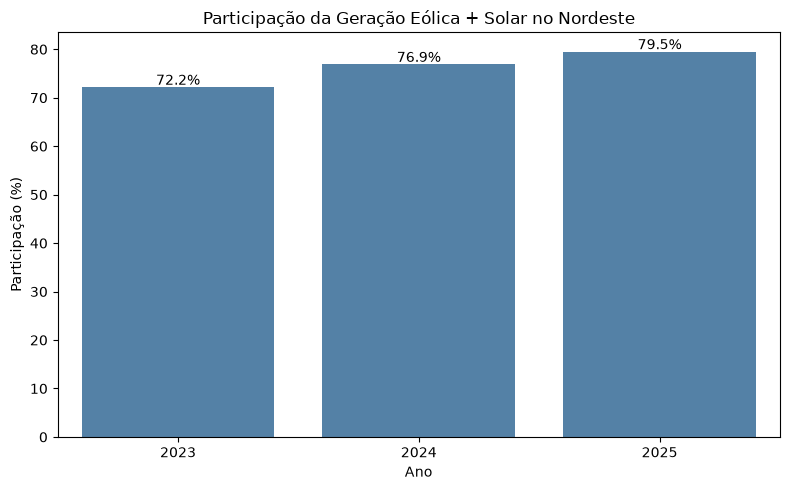

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

ax = sns.barplot(
    data=resultado_final,
    x='ano',
    y='percentual_eolica_solar',
    color='steelblue'
)

for i, v in enumerate(resultado_final['percentual_eolica_solar']):
    ax.text(i, v + 0.5, f'{v:.1f}%', ha='center')

plt.title('Participação da Geração Eólica + Solar no Nordeste')
plt.xlabel('Ano')
plt.ylabel('Participação (%)')

plt.tight_layout()
plt.show()

### Registro de interpretação da análise acima
A participação da geração eólica e solar no Nordeste apresentou crescimento contínuo, passando de 72,2% em 2023 para 79,5% em 2025, um aumento de 7,3 pontos percentuais em apenas três anos, evidenciando o avanço da transição energética e a crescente relevância dessas fontes na matriz regional

## 7. Agregação mensal

Plotagem dos intercâmbios de energia mensais entre os subsistemas Norte, Nordeste, Sudeste e Sul.

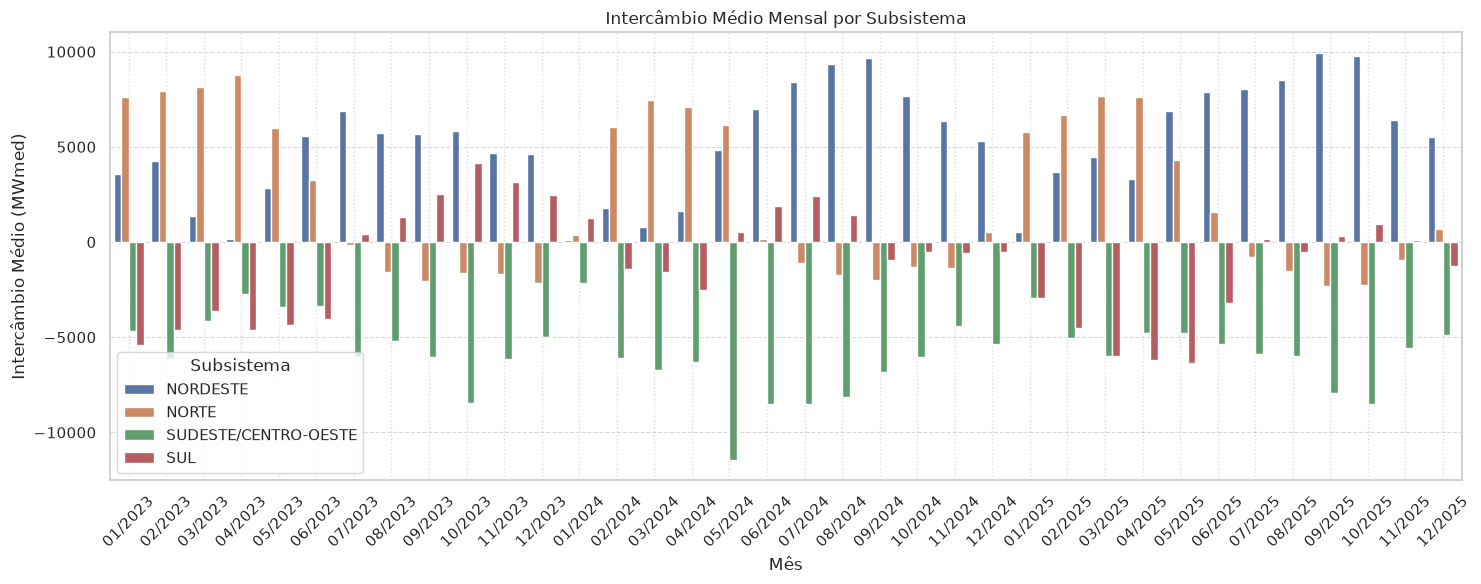

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

# Remove o SIN
dados_filtrado = dados[
    dados['subsistema'] != 'SISTEMA INTERLIGADO NACIONAL'
]

# Média mensal por subsistema
mensal = (
    dados_filtrado
    .groupby([
        pd.Grouper(key='data', freq='ME'),
        'subsistema'
    ])['val_intercambio']
    .mean()
    .reset_index()
)

# Formata a data para exibição
mensal['mes_ano'] = mensal['data'].dt.strftime('%m/%Y')

# Configuração visual
sns.set_theme(style="whitegrid")

# Gráfico
plt.figure(figsize=(15, 6))

ax = sns.barplot(
    data=mensal,
    x='mes_ano',
    y='val_intercambio',
    hue='subsistema'
)

# Grade horizontal
ax.grid(
    axis='y',
    color='gray',
    linestyle='--',
    linewidth=0.8,
    alpha=0.3
)

# Grade vertical
ax.grid(
    axis='x',
    color='lightgray',
    linestyle=':',
    linewidth=1,
    alpha=0.8
)

plt.title('Intercâmbio Médio Mensal por Subsistema')
plt.xlabel('Mês')
plt.ylabel('Intercâmbio Médio (MWmed)')
plt.xticks(rotation=45)
plt.legend(title='Subsistema')

plt.tight_layout()
plt.show()

### Registro de interpretação da análise acima
Conclui-se que a região Nordeste foi exportadora de energia em todos os meses do período analisado.

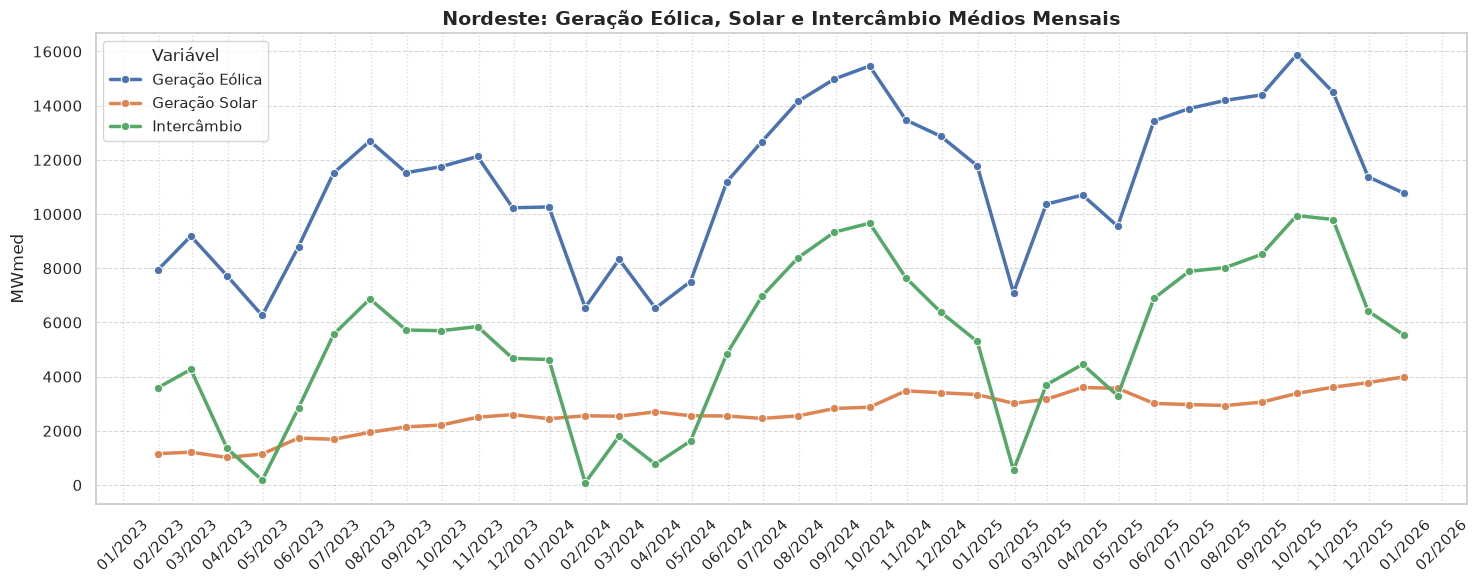

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Filtra o Nordeste
dados_ne = dados[
    dados['subsistema'] == 'NORDESTE'
].copy()

# Médias mensais
mensal = (
    dados_ne
    .groupby(pd.Grouper(key='data', freq='ME'))
    [['val_gereolica', 'val_gersolar', 'val_intercambio']]
    .mean()
    .reset_index()
)

# Converte para formato longo
mensal_long = mensal.melt(
    id_vars='data',
    value_vars=[
        'val_gereolica',
        'val_gersolar',
        'val_intercambio'
    ],
    var_name='Variável',
    value_name='Valor'
)

# Renomeia para legenda
mensal_long['Variável'] = mensal_long['Variável'].replace({
    'val_gereolica': 'Geração Eólica',
    'val_gersolar': 'Geração Solar',
    'val_intercambio': 'Intercâmbio'
})

# Configuração visual
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(15, 6))

sns.lineplot(
    data=mensal_long,
    x='data',
    y='Valor',
    hue='Variável',
    marker='o',
    linewidth=2.5,
    ax=ax
)

# Grade mensal
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))

# Grade vertical
ax.grid(
    axis='x',
    color='lightgray',
    linestyle=':',
    linewidth=1,
    alpha=0.8
)

# Grade horizontal
ax.grid(
    axis='y',
    color='gray',
    linestyle='--',
    linewidth=0.8,
    alpha=0.3
)

ax.set_title(
    'Nordeste: Geração Eólica, Solar e Intercâmbio Médios Mensais',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('')
ax.set_ylabel('MWmed')

plt.xticks(rotation=45)
plt.legend(title='Variável')

plt.tight_layout()
plt.show()

### Registro de interpretação da análise acima
O gráfico acima constata que o intercâmbio do Nordeste é sempre positivo e acompanha a característica mensal da geração eólica+solar

In [13]:
mensal['renovavel'] = (
    mensal['val_gereolica']
    + mensal['val_gersolar']
)

correlacao = mensal['renovavel'].corr(
    mensal['val_intercambio']
)

print(correlacao)

0.9505463494579041


Como coeficiente de correlação de Pearson entre a geração renovável do Nordeste (eólica + solar) e o intercâmbio do subsistema Nordeste ao longo do período analisado foi 0,951, indicando uma correlação positiva extremamente forte. Esse resultado demonstra que os períodos de maior geração renovável coincidem com maiores volumes de exportação de energia pelo Nordeste para os demais subsistemas do Sistema Interligado Nacional (SIN). Embora a correlação não estabeleça causalidade por si só, a elevada associação observada é coerente com a expansão das fontes eólica e solar na região e com o papel crescente do Nordeste como exportador de energia para o restante do país.

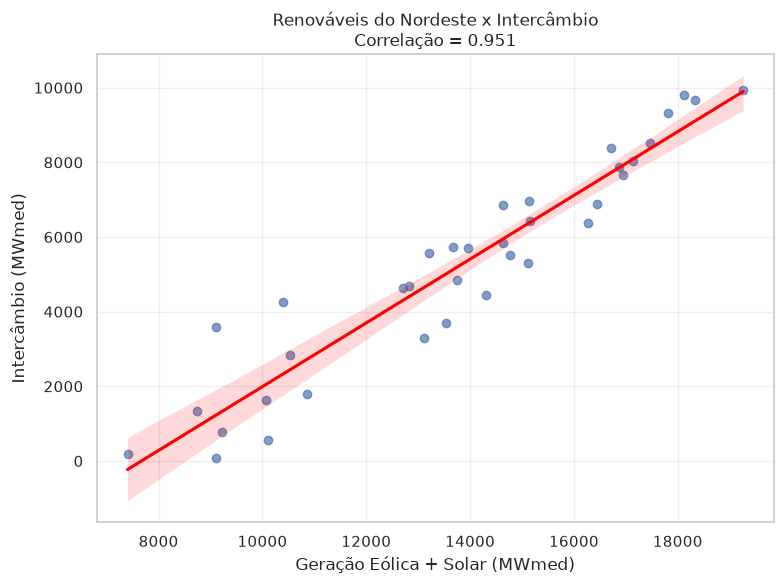

In [14]:
mensal['renovavel'] = (
    mensal['val_gereolica']
    + mensal['val_gersolar']
)

plt.figure(figsize=(8,6))

sns.regplot(
    data=mensal,
    x='renovavel',
    y='val_intercambio',
    scatter_kws={'alpha':0.7},
    line_kws={'color':'red'}
)

plt.title(
    f'Renováveis do Nordeste x Intercâmbio\nCorrelação = {correlacao:.3f}'
)

plt.xlabel('Geração Eólica + Solar (MWmed)')
plt.ylabel('Intercâmbio (MWmed)')

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Esse gráfico mostra visualmente que os pontos praticamente se alinham a uma reta crescente, reforçando a correlação de 0,951.


## 8. Avaliação da participação das exportações do Nordeste no atendimento das cargas dos demais subsistemas

In [15]:
dados_filtrado = dados[
    dados['subsistema'].isin([
        'NORDESTE',
        'NORTE',
        'SUL',
        'SUDESTE/CENTRO-OESTE'
    ])
].copy()

dados_filtrado['ano'] = dados_filtrado['data'].dt.year

carga_outros = (
    dados_filtrado[
        dados_filtrado['subsistema'] != 'NORDESTE'
    ]
    .groupby('ano')['val_carga']
    .sum()
)

exp_ne = (
    dados_filtrado[
        dados_filtrado['subsistema'] == 'NORDESTE'
    ]
    .groupby('ano')['val_intercambio']
    .sum()
)

resultado = pd.DataFrame({
    'exportacao_ne': exp_ne,
    'carga_outros': carga_outros
})

resultado['perc_carga_outros'] = (
    resultado['exportacao_ne']
    / resultado['carga_outros']
    * 100
)

display(resultado)

,exportacao_ne,carga_outros,perc_carga_outros
ano,,,
2023,3.742029e+07,5.395111e+08,6.935962
2024,4.604660e+07,5.781774e+08,7.964096
2025,5.486827e+07,5.811563e+08,9.441224


In [16]:
# Subsistemas de interesse
dados_filtrado = dados[
    dados['subsistema'].isin([
        'NORDESTE',
        'NORTE',
        'SUL',
        'SUDESTE/CENTRO-OESTE'
    ])
].copy()

dados_filtrado['ano'] = dados_filtrado['data'].dt.year

# Exportação do Nordeste
exportacao_ne = (
    dados_filtrado[
        dados_filtrado['subsistema'] == 'NORDESTE'
    ]
    .groupby('ano')['val_intercambio']
    .sum()
)

# Carga do Nordeste
carga_ne = (
    dados_filtrado[
        dados_filtrado['subsistema'] == 'NORDESTE'
    ]
    .groupby('ano')['val_carga']
    .sum()
)

# Carga dos demais subsistemas
carga_outros = (
    dados_filtrado[
        dados_filtrado['subsistema'] != 'NORDESTE'
    ]
    .groupby('ano')['val_carga']
    .sum()
)

# Participação eólica + solar no Nordeste
dados_ne = dados_filtrado[
    dados_filtrado['subsistema'] == 'NORDESTE'
].copy()

dados_ne['geracao_total'] = (
    dados_ne['val_gerhidraulica']
    + dados_ne['val_gertermica']
    + dados_ne['val_gereolica']
    + dados_ne['val_gersolar']
)

renovavel = (
    dados_ne
    .groupby('ano')
    .agg({
        'val_gereolica':'sum',
        'val_gersolar':'sum',
        'geracao_total':'sum'
    })
)

renovavel['perc_eolica_solar'] = (
    (renovavel['val_gereolica'] + renovavel['val_gersolar'])
    / renovavel['geracao_total']
    * 100
)

# Tabela consolidada
tabela_final = pd.DataFrame({
    'Exportação Nordeste (MWmed.h)': exportacao_ne,
    'Carga Nordeste (MWmed.h)': carga_ne,
    'Carga Restante SIN (MWmed.h)': carga_outros,
    '% Carga Restante Atendida': (
        exportacao_ne / carga_outros * 100
    ),
    '% Eólica + Solar no NE': renovavel['perc_eolica_solar']
})

# Arredondamento
tabela_final = tabela_final.round(2)

display(tabela_final)

,Exportação Nordeste (MWmed.h),Carga Nordeste (MWmed.h),Carga Restante SIN (MWmed.h),% Carga Restante Atendida,% Eólica + Solar no NE
ano,,,,,
2023,37420289.00,1.061446e+08,5.395112e+08,6.94,72.19
2024,46046603.75,1.152601e+08,5.781774e+08,7.96,76.90
2025,54868265.53,1.162177e+08,5.811563e+08,9.44,79.52


### Conclusão
- **1:** O subsistema Nordeste conforme gráfico da média mensal é sempre exportador de energia para os demais subsistemas. Bem evidenciado através do gráfico de barras, onde o intercâmbio do subsistema Nordeste tem sempre valor positivo. Isso acontece porque a geração do Nordeste é maior que sua carga, implicando em excedente de geração.
- **2:** A geração eólica e solar do Nordeste são as fontes que tem mais contribuido para o subsistema Nordeste ser exportador de energia. 
- **3:** A participação da geração excedente do Nordeste no atendimento às cargas do restante do País tem crescido ao longo dos anos variando de quase 7% em 2023 até quase 10% em 2025.
- **4:** Adicionalmente, a correlação de Pearson de 0,951 entre a geração eólica+solar e o intercâmbio do Nordeste evidenciou uma associação extremamente forte entre a expansão das fontes renováveis e o aumento das exportações de energia. Os resultados demonstram que o Nordeste vem assumindo papel cada vez mais estratégico na segurança energética brasileira, contribuindo de forma crescente para o suprimento das cargas das demais regiões do país por meio da expansão das fontes renováveis.


